In [1]:
import glob
import numpy as np

import blue_labels as bl

from skimage import io, morphology, transform

from corebreakout.segmentation.utils import crop_tray_cols, mirror_pad
from corebreakout.utils.viz_utils import show_images

In [2]:
dropbox_dir = '/home/administrator/Dropbox/core_data/segmentation/'

raw_files = sorted([f for f in glob.glob(dropbox_dir+'*.jpeg')])

img_files = [f for f in raw_files if 'BlueLabel' not in f]
label_files = [f for f in raw_files if 'BlueLabel' in f]

list(zip(img_files, label_files))

[('/home/administrator/Dropbox/core_data/segmentation/S00082679.jpeg',
  '/home/administrator/Dropbox/core_data/segmentation/S00082679_BlueLabel.jpeg'),
 ('/home/administrator/Dropbox/core_data/segmentation/S00082684.jpeg',
  '/home/administrator/Dropbox/core_data/segmentation/S00082684_BlueLabel.jpeg'),
 ('/home/administrator/Dropbox/core_data/segmentation/S00092805.jpeg',
  '/home/administrator/Dropbox/core_data/segmentation/S00092805_BlueLabel.jpeg'),
 ('/home/administrator/Dropbox/core_data/segmentation/S00096687.jpeg',
  '/home/administrator/Dropbox/core_data/segmentation/S00096687_BlueLabel.jpeg'),
 ('/home/administrator/Dropbox/core_data/segmentation/S00098851.jpeg',
  '/home/administrator/Dropbox/core_data/segmentation/S00098851_BlueLabel.jpeg'),
 ('/home/administrator/Dropbox/core_data/segmentation/S00101424.jpeg',
  '/home/administrator/Dropbox/core_data/segmentation/S00101424_BlueLabel.jpeg'),
 ('/home/administrator/Dropbox/core_data/segmentation/S00102592.jpeg',
  '/home/ad

In [3]:
# first one (depth-named) a mismatch
imgs = [io.imread(f) for f in img_files]
labels = [io.imread(f) for f in label_files]

In [4]:
type_B = ['S00092805.jpeg',
          'S00146624.jpeg',
          'S00146633.jpeg',
          'S00170017.jpeg']

In [5]:
def op(m):
    image = morphology.remove_small_holes(m, area_threshold=1000)
    image = morphology.remove_small_objects(m, min_size=500)
    return image

cimgs = []
masks = []
for fname, img, label in zip(img_files, imgs, labels):
    print(fname)
    if fname.split('/')[-1] in type_B:
        config_key = 'B'
    else:
        config_key = 'A'
        
    img_cols = crop_tray_cols(img, config_key)
    mask_cols = crop_tray_cols(label, config_key)
    for icol, mcol in zip(img_cols, mask_cols):
        cimgs.append(transform.rescale(icol, 0.25, multichannel=True))
        mask = bl.generate_mask(mcol, (0,0,254), morph_op = op)
        masks.append(transform.rescale(mask, 0.25, multichannel=False))

/home/administrator/Dropbox/core_data/segmentation/S00082679.jpeg


/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:105: UserWarning: The default mode, 'constant', will be changed to 'reflect' in skimage 0.15.
  warn("The default mode, 'constant', will be changed to 'reflect' in "
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


/home/administrator/Dropbox/core_data/segmentation/S00082684.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00092805.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00096687.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00098851.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00101424.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00102592.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00102673.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00102695.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00102699.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00102702.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00106067.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00106078.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00106080.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00106099.jpeg
/home/administrator/Dropbox/core_data/segmentation/S00106960.jpeg
/home/admi

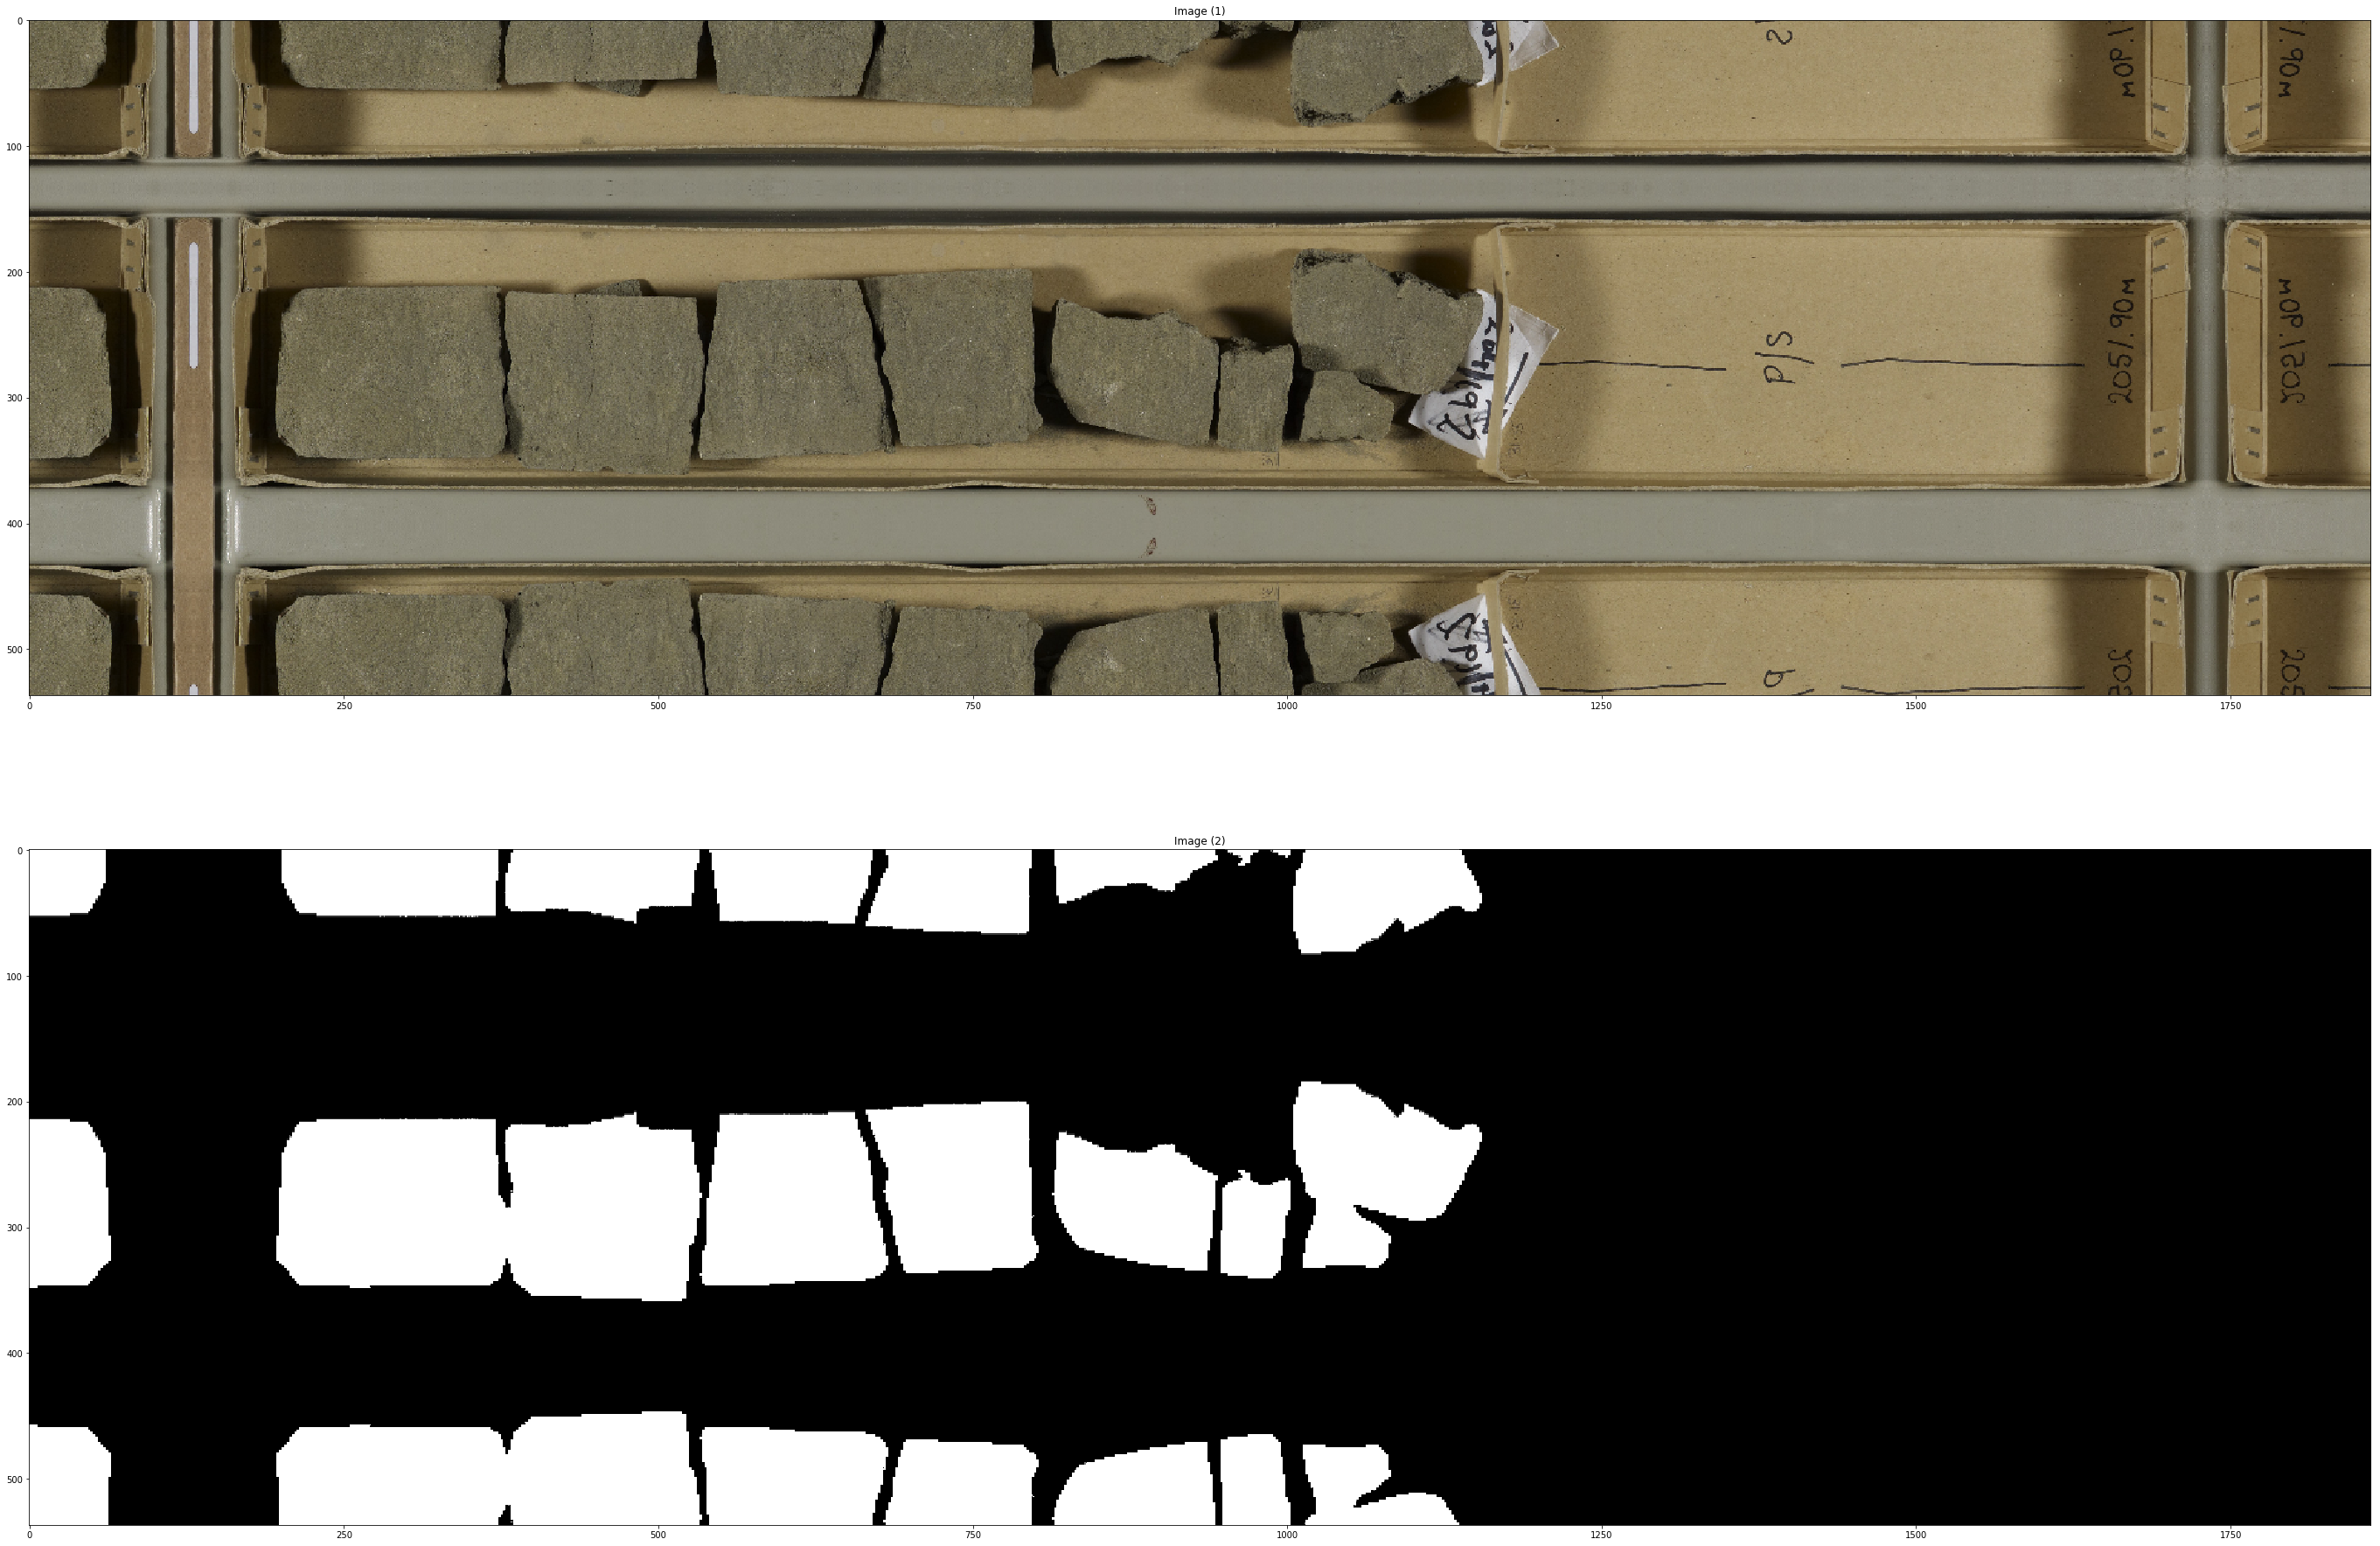

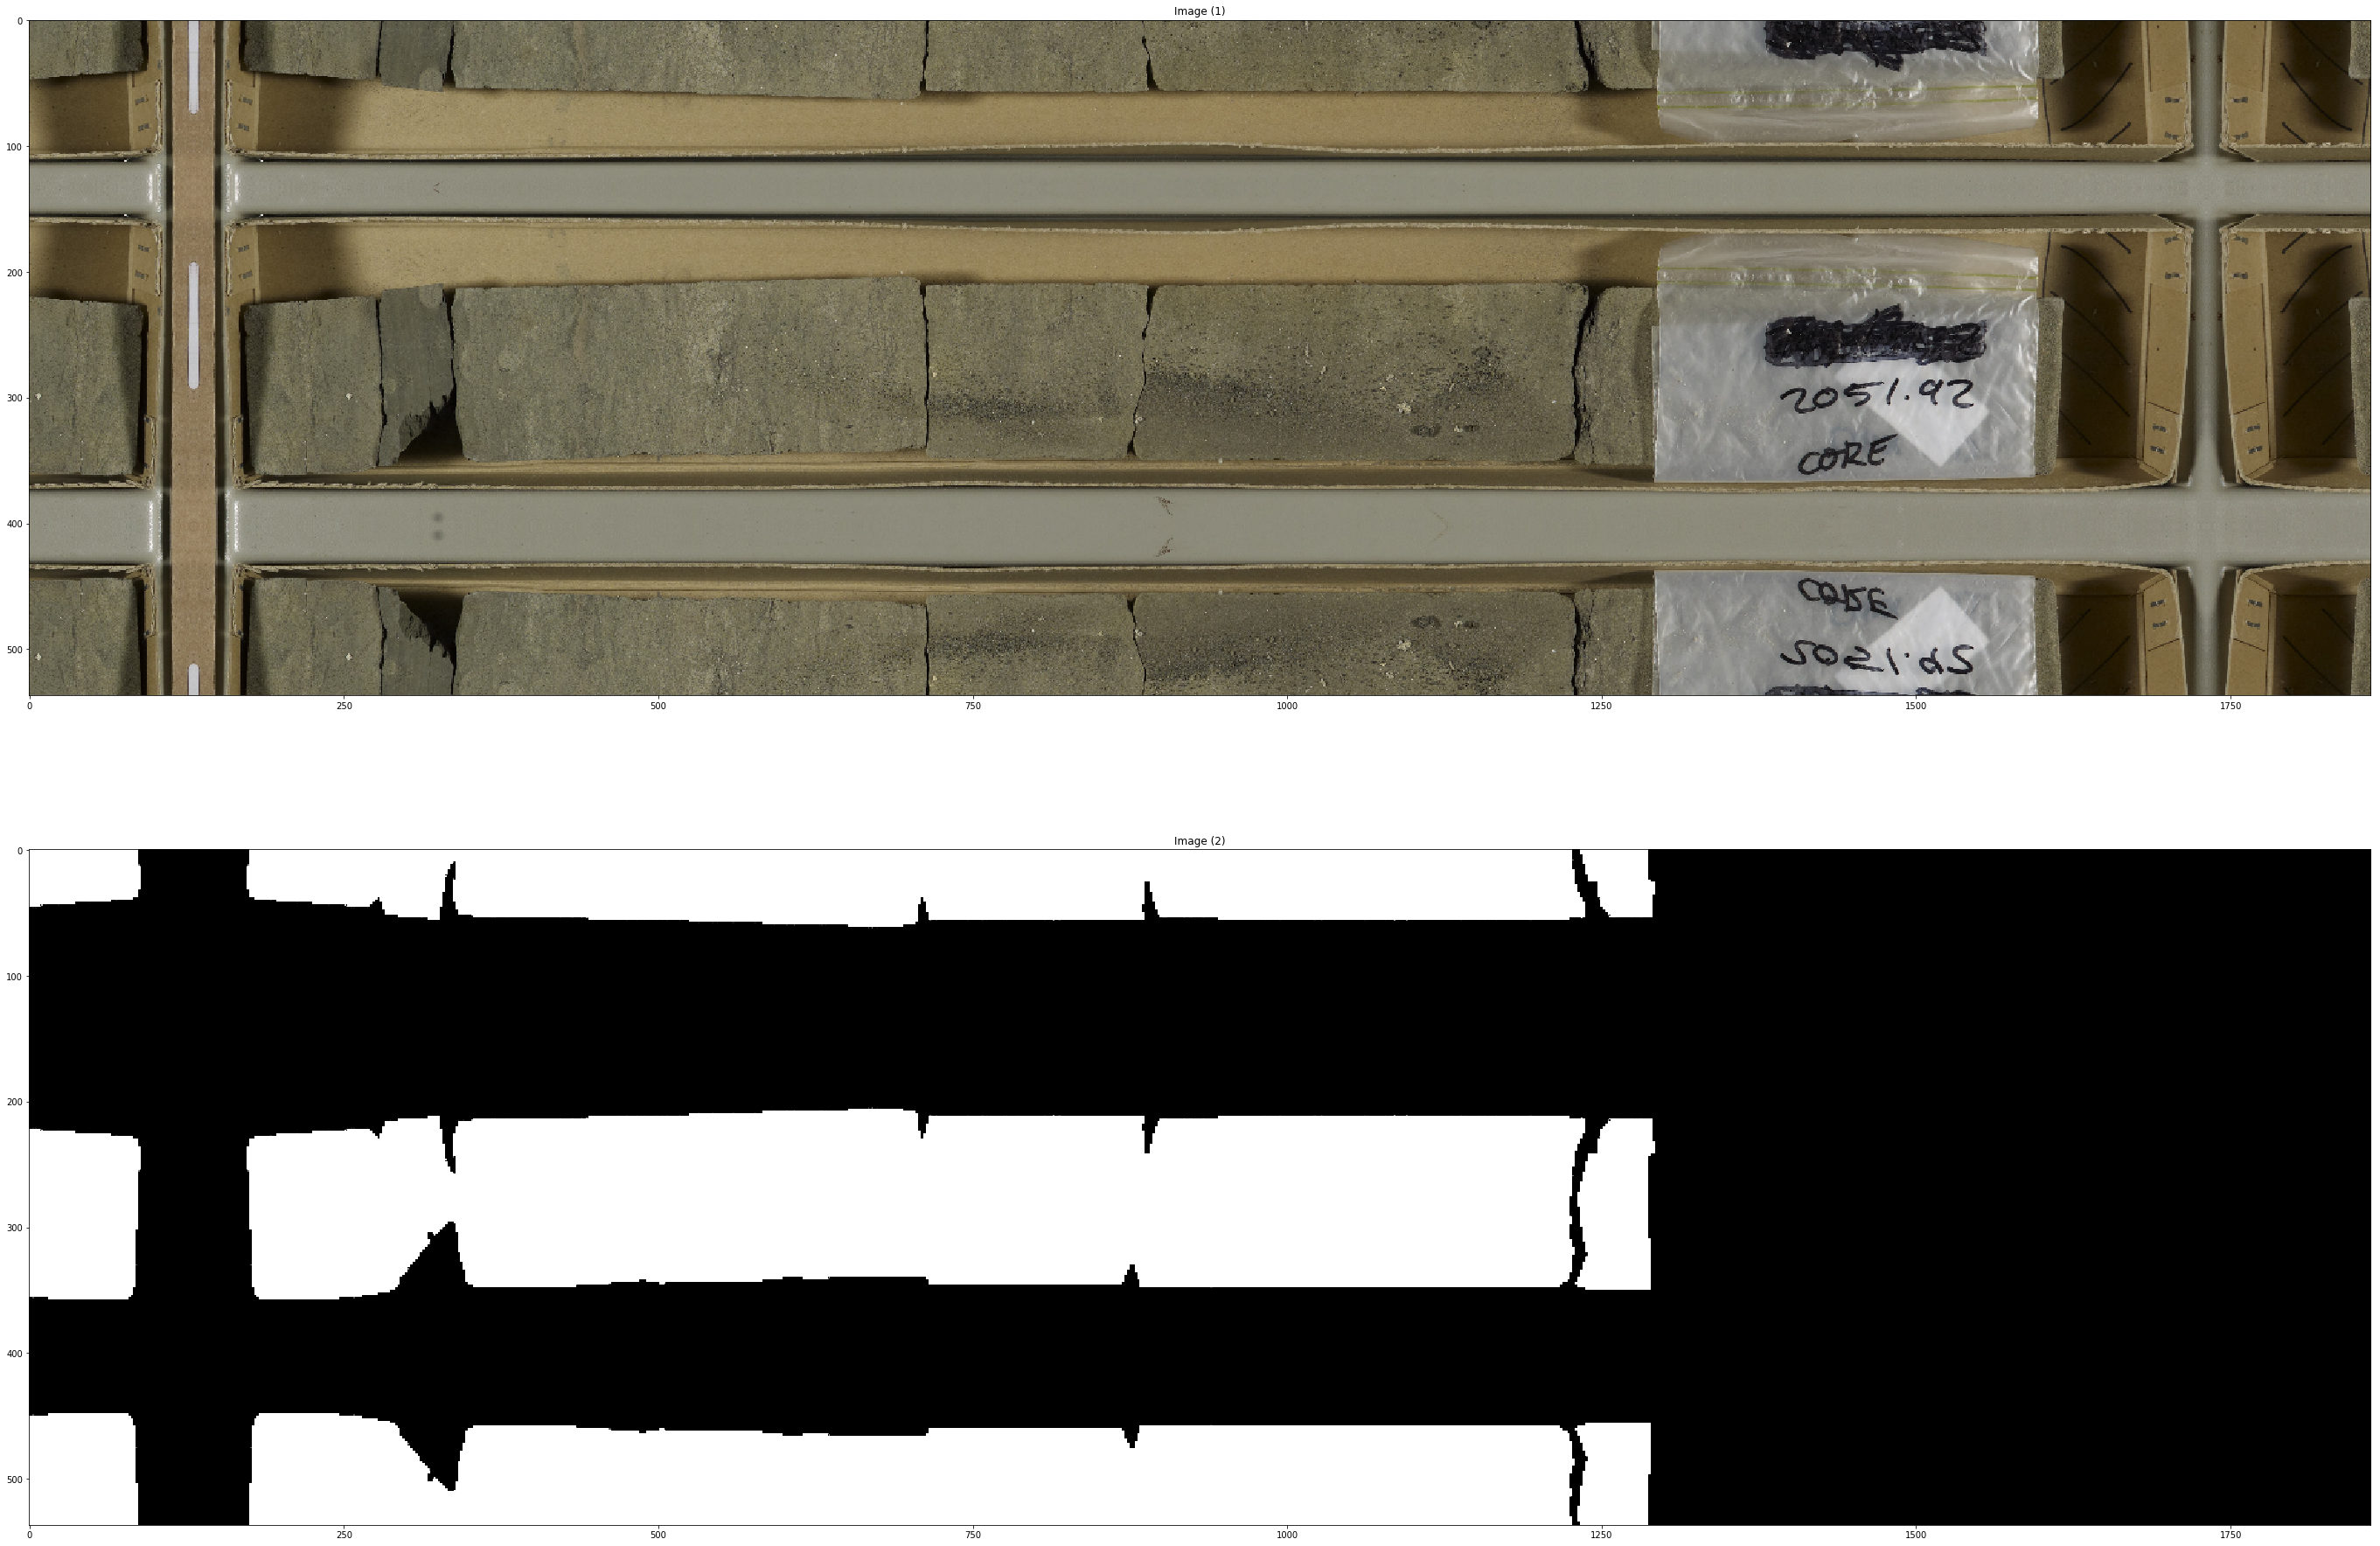

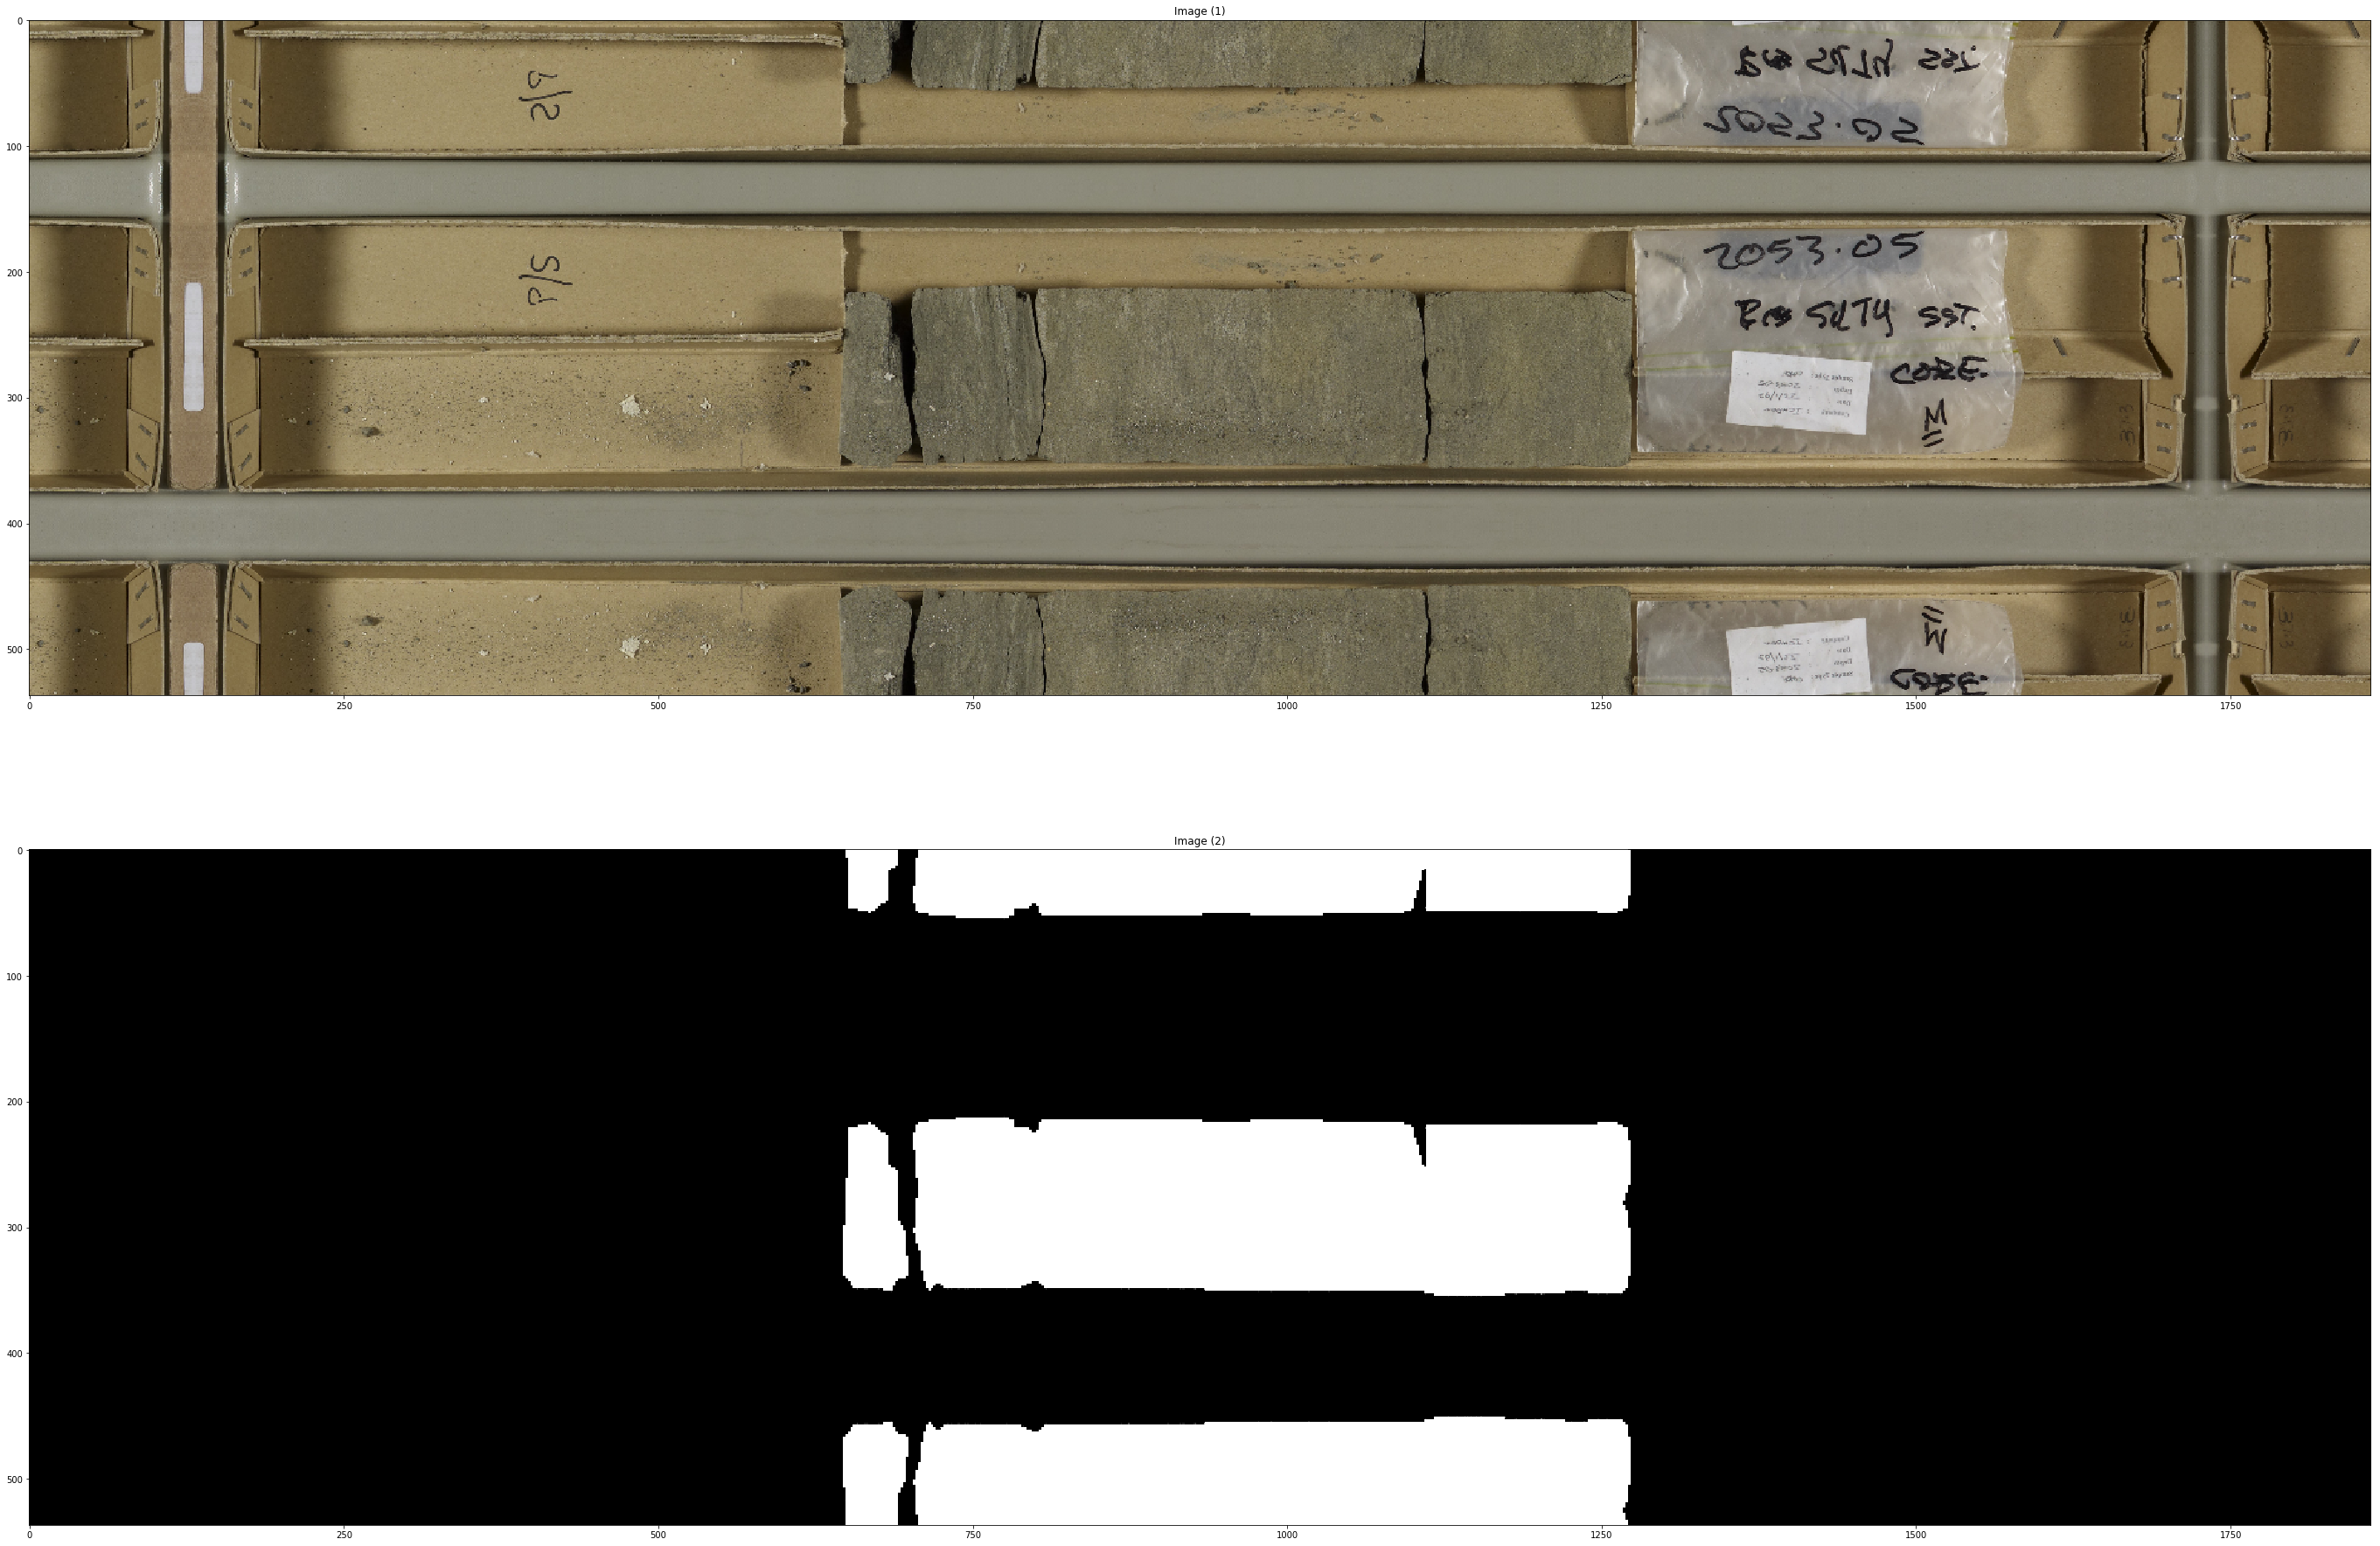

In [30]:
for img, mask in zip(cimgs[0:3], masks):
    # using largest (shape*0.25) that has (out*0.75) % 2 == 0.
    pimg = mirror_pad(img, (536, 1862))
    pmask = mirror_pad(mask, (536, 1862))
    show_images([pimg, pmask], cols=2)

In [31]:
col_dir = '/home/administrator/Dropbox/core_data/segmentation/royal_col_images/'
mask_dir = '/home/administrator/Dropbox/core_data/segmentation/royal_col_masks/'

for i, (img, mask) in enumerate(zip(cimgs, masks)):
    name = 'col_'+str(i)+'.jpeg'
    img = mirror_pad(img, (536, 1862))
    mask = mirror_pad(mask, (536, 1862))
    io.imsave(col_dir+name, img)
    io.imsave(mask_dir+name, (mask>0).astype(np.uint8))

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:130: UserWarning: Possible precision loss when converting from float64 to uint8
  .format(dtypeobj_in, dtypeobj_out))
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_0.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_1.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_2.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/ana

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_32.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_33.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_34.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_masks/col_35.jpeg is a low contrast image
  warn('%s is a low c

In [23]:
shapes = np.array([i.shape for i in cimgs])
shapes.max(axis=0)

array([ 350, 1675,    3])

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:24: UserWarning: The default multichannel argument (None) is deprecated.  Please specify either True or False explicitly.  multichannel will default to False starting with release 0.16.
  warn('The default multichannel argument (None) is deprecated.  Please '
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:105: UserWarning: The default mode, 'constant', will be changed to 'reflect' in skimage 0.15.
  warn("The default mode, 'constant', will be changed to 'reflect' in "
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:110: UserWarning: Anti-aliasing will be enabled by default in skimage 0.15 to avoid aliasing artifacts when down-sampling images.
  warn("Anti-aliasing will be enabled by default in skimage 0.15 to "


(1220, 1788, 3)

In [24]:
shapes.min(axis=0)

array([ 238, 1600,    3])

In [25]:
350+186

536

In [27]:
1676+186

1862

In [21]:
1408/3.0

469.3333333333333

In [29]:
1676*0.75

1257.0